# EEG Microstate Tokenisation — Hilbert VQ-VAE: steps 1-3 (config, segment, codebook sweep)

This notebook runs the **interactive** part of the pipeline:
1. **Configuration** — set the continuous-record path, segment length (scale), descriptor, filterbank.
2. **Build dataset** — segment the continuous record(s) into whole-segment instances (chunk = instance).
3. **Codebook-size sweep** — train one model per candidate K and plot the elbow.

Inspect the elbow, choose **K**, then run the end-to-end finaliser:

```
python fit_vqvae.py --sweep <prefix>_sweep.pt --codebook-size K
```

The finaliser loads the already-trained sweep model for K (no retraining; pass
`--retrain` to refit for FULL_EPOCHS), prunes, tokenises, and saves all outputs
plus the three fitting figures (training curves, codebook pruning, filter bands).


In [ ]:
import numpy as np
import torch
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader

from models.hilbert_vqvae import HilbertVQVAE, relative_recon_error
from models.descriptors import DESCRIPTOR_REGISTRY, suggest_freq_low
from models.early_stopping import EarlyStopping
from models.utils import UnsupervisedEEGDataset, segment_records, split_segments

print('Available descriptors:', list(DESCRIPTOR_REGISTRY.keys()))


## 1. Configuration

In [ ]:
# ── Parameters you set ───────────────────────────────────────────────
subid = '20221005_R'
DATA_PATH      = f'/data/1overf/Cleaned_data/{subid}.npy'           # continuous record(s)
FS             = 200                  # sampling frequency (Hz)

# ── SCALE PARAMETER ──────────────────────────────────────────────────
# The continuous record is cut into non-overlapping segments of this length,
# and EACH WHOLE SEGMENT is one instance (chunk = instance; no sub-chunking).
# Sweep SEGMENT_SEC to compare the model at different timescales.
SEGMENT_SEC    = 2.0                  # segment / instance length (seconds)

FILT_DIM       = 145                  # filter kernel length (frequency resolution)

DESCRIPTOR     = 'coherence'          # 'amplitude' | 'cross_spectral'
                                      # | 'complex_correlation' | 'coherence'

# ── Filterbank: choose ONE of the two modes ──────────────────────────
# Mode A — FIXED bands (recommended for interpretable microstates):
#   filters are frozen to exactly these (low, high) Hz bands, guaranteeing
#   full spectral coverage. N_FILT is set to the number of bands.
FIXED_BANDS = [(4, 8), (8, 12), (12, 20), (20, 30), (30, 45)]   # e.g. theta..gamma
#
# Mode B — LEARNABLE filters: set FIXED_BANDS = None and specify N_FILT and the
#   trainable frequency range [FREQ_LOW, FREQ_HIGH].
N_FILT         = 20                   # used only when FIXED_BANDS is None
FREQ_LOW       = 4.0                  # used only when FIXED_BANDS is None
FREQ_HIGH      = 45.0                 # used only when FIXED_BANDS is None
MIN_BAND       = 2.0
CUTOFF         = 50.0                 # absolute ceiling (e.g. preprocessing bandpass)

CODEBOOK_SIZES = [8, 16, 24, 32, 40, 48, 56, 64]

# Tokenisation hop: None -> non-overlapping segments (one token per segment,
# step == segment). Set to an int (samples) for overlapping tokenisation.
TOKENISE_STEP_SAMPLES = None

PRUNE_PCT      = 2.0                  # prune codebook entries used in < this % of
                                      # segments (remap to nearest survivor); 0 disables
VAL_FRACTION   = 0.2                  # held out: whole records if >1 record,
                                      # else a contiguous tail block of segments

CODEBOOK_DIM   = 512  #amplitude 128 coherence 512 
DECODER_HIDDEN = 1024  # amplitude 256 coherence 1024
ENCODER_HIDDEN = None  # None = linear proj_down (default, interpretable token
                       # geometry). Set an int (e.g. 1024) for a nonlinear
                       # encoder bottleneck -> learned quantization metric;
                       # compare recon error and codebook diagnostics at matched K.
BATCH_SIZE     = 64
LR             = 3e-4
SWEEP_EPOCHS   = 200
FULL_EPOCHS    = 300
PATIENCE       = 20

# ── Derived ───────────────────────────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load continuous record(s). Accepts:
#   (C, T)      one continuous recording
#   (N, C, T)   several continuous recordings (split by record)
#   object array / list of (C, T) recordings of differing length
raw = np.load(DATA_PATH, allow_pickle=True)
if isinstance(raw, np.ndarray) and raw.dtype == object:
    records = [np.asarray(r) for r in raw]            # list of (C, T)
    C = records[0].shape[0]
    n_records = len(records)
    total_T = sum(r.shape[1] for r in records)
elif raw.ndim == 2:
    records = raw                                     # single (C, T)
    C = raw.shape[0]
    n_records = 1
    total_T = raw.shape[1]
elif raw.ndim == 3:
    records = raw                                     # (N, C, T)
    C = raw.shape[1]
    n_records = raw.shape[0]
    total_T = raw.shape[0] * raw.shape[2]
else:
    raise ValueError(f'unexpected data shape {raw.shape}')

SEGMENT_SAMPLES = int(SEGMENT_SEC * FS)

# resolve number of filters
if FIXED_BANDS is not None:
    EFFECTIVE_N_FILT = len(FIXED_BANDS)
else:
    EFFECTIVE_N_FILT = N_FILT

_desc_dim = {
    'amplitude':           EFFECTIVE_N_FILT * C,
    'cross_spectral':      EFFECTIVE_N_FILT * C * C,
    'complex_correlation': EFFECTIVE_N_FILT * C * (C - 1),
    'coherence':           EFFECTIVE_N_FILT * (C * (C - 1)) // 2,
}[DESCRIPTOR]

print(f'Device:      {device}')
print(f'Records:     {n_records}  (C={C}, total samples={total_T})')
print(f'Segment:     {SEGMENT_SEC}s = {SEGMENT_SAMPLES} samples  (chunk = instance)')
print(f'Descriptor:  {DESCRIPTOR}  ->  d_desc = {_desc_dim}')
if FIXED_BANDS is not None:
    print(f'Filterbank:  FIXED, {EFFECTIVE_N_FILT} bands: {FIXED_BANDS}')
else:
    print(f'Filterbank:  LEARNABLE, N_FILT={N_FILT}, range [{FREQ_LOW},{FREQ_HIGH}] Hz')

# ── Advisory: minimum reliable frequency for the chosen descriptor ─────
adv = suggest_freq_low(SEGMENT_SAMPLES, FS, DESCRIPTOR)
print()
print(f'ADVISORY for "{DESCRIPTOR}": >= {adv["min_cycles"]:.0f} cycles/segment '
      f'-> frequencies should be >= {adv["freq_low_min"]:.2f} Hz')
if FIXED_BANDS is not None:
    too_low = [b for b in FIXED_BANDS if b[0] < adv['freq_low_min']]
    if too_low:
        print(f'  ** WARNING: these fixed bands start below {adv["freq_low_min"]:.2f} Hz '
              f'and may give unreliable {DESCRIPTOR}: {too_low}')
    else:
        print(f'  All fixed bands satisfy the recommendation.')
else:
    if FREQ_LOW < adv['freq_low_min']:
        print(f'  ** WARNING: FREQ_LOW={FREQ_LOW} < {adv["freq_low_min"]:.2f} Hz — '
              f'low-frequency {DESCRIPTOR} may be unreliable.')
    else:
        print(f'  FREQ_LOW={FREQ_LOW} satisfies the recommendation.')


## 2. Build dataset (segment the continuous record)

In [ ]:
# Cut the continuous record(s) into whole-segment instances (chunk = instance).
# Each segment is ONE instance / ONE window — there is no sub-chunking.
segments, seg_starts, seg_record_id = segment_records(
    records, SEGMENT_SAMPLES, step_samples=None)   # non-overlapping
print(f'Segments: {segments.shape}  (one whole segment = one instance = one window)')

# Leakage-safe split: by record if >1 record, else a contiguous tail block.
tr_mask, val_mask = split_segments(seg_record_id, val_fraction=VAL_FRACTION, seed=42)
X_train, X_val = segments[tr_mask], segments[val_mask]
print(f'Train {len(X_train)} | Val {len(X_val)} segments '
      f'({"split by record" if len(np.unique(seg_record_id))>1 else "contiguous tail block"})')

train_loader = DataLoader(UnsupervisedEEGDataset(X_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(UnsupervisedEEGDataset(X_val),   batch_size=BATCH_SIZE, shuffle=False)
full_loader  = DataLoader(UnsupervisedEEGDataset(segments),batch_size=BATCH_SIZE, shuffle=False)


## 3. Codebook size sweep

In [ ]:
def build_model(codebook_size):
    return HilbertVQVAE(
        num_EEG_Channels=C, N_filt=N_FILT, Filt_dim=FILT_DIM,
        window_samples=SEGMENT_SAMPLES, descriptor=DESCRIPTOR,
        fs=FS, cutoff=CUTOFF,
        freq_low=FREQ_LOW, freq_high=FREQ_HIGH, min_band=MIN_BAND,
        fixed_bands=FIXED_BANDS,
        codebook_size=codebook_size,
        codebook_dim=CODEBOOK_DIM, decoder_hidden=DECODER_HIDDEN,
        encoder_hidden=ENCODER_HIDDEN,
    ).to(device)


def train_model(model, train_loader, val_loader, n_epochs, patience=PATIENCE,
                checkpoint_path='ckpt.pt',
                collapse_active_frac=0.25, collapse_dist=0.05,
                collapse_patience=5, verbose=True):
    """
    Train with val early stopping AND a sign-independent collapse auto-stop.

    Returns (history, stop_reason) where history is a dict of per-epoch lists:
        'train_loss'  mean training total loss
        'val_loss'    mean validation total loss
        'train_recon' mean training reconstruction loss
        'val_recon'   mean validation reconstruction loss
        'val_err'     mean validation relative reconstruction error
        'active'      active codebook entries
        'dist'        mean normalised pairwise codebook distance
    stop_reason in {'val_loss','collapse','max_epochs'}.
    """
    optimizer = optim.Adam(model.parameters(), lr=LR)
    stopper   = EarlyStopping(patience=patience, path=checkpoint_path)
    history = {k: [] for k in
               ['train_loss','val_loss','train_recon','val_recon','val_err','active','dist']}
    collapse_count, stop_reason = 0, 'max_epochs'

    for epoch in range(n_epochs):
        # ---- train ----
        model.train(); tl = tr = 0.0
        for batch in train_loader:
            batch = batch.to(device)
            _, _, _, losses = model(batch)
            optimizer.zero_grad(); losses['total'].backward(); optimizer.step()
            tl += losses['total'].item(); tr += losses['recon'].item()
        n_tr = len(train_loader)

        # ---- validate ----
        model.eval(); vl = vr = ve = 0.0
        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(device)
                dh, dt, _, losses = model(batch)
                vl += losses['total'].item(); vr += losses['recon'].item()
                ve += relative_recon_error(dh, dt)
        n_va = len(val_loader)

        diag = model.quantizer.codebook_diagnostics()
        history['train_loss'].append(tl/n_tr)
        history['val_loss'].append(vl/n_va)
        history['train_recon'].append(tr/n_tr)
        history['val_recon'].append(vr/n_va)
        history['val_err'].append(ve/n_va)
        history['active'].append(diag['active_entries'])
        history['dist'].append(diag['mean_norm_dist'])

        if verbose and epoch % 10 == 0:
            print(f'  epoch {epoch:3d} | train {history["train_loss"][-1]:.4f} | '
                  f'val {history["val_loss"][-1]:.4f} | err {history["val_err"][-1]*100:.2f}% | '
                  f'active {diag["active_entries"]}/{model.codebook_size} | '
                  f'dist {diag["mean_norm_dist"]:.3f}')

        # sign-independent collapse
        if diag['active_fraction'] < collapse_active_frac and diag['mean_norm_dist'] < collapse_dist:
            collapse_count += 1
            if collapse_count >= collapse_patience:
                print(f'  collapsed at epoch {epoch}')
                stop_reason='collapse'; break
        else:
            collapse_count = 0

        stopper(history['val_loss'][-1], model)
        if stopper.early_stop: stop_reason='val_loss'; break

    if stop_reason != 'collapse':
        model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    return history, stop_reason

In [75]:
sweep_errors, sweep_models, sweep_reasons, sweep_histories = {}, {}, {}, {}
for K in CODEBOOK_SIZES:
    print(f'Training K={K}...')
    m = build_model(K)
    hist, reason = train_model(m, train_loader, val_loader, n_epochs=SWEEP_EPOCHS,
                               checkpoint_path=f'ckpt_K{K}.pt', verbose=False)
    sweep_histories[K] = hist
    sweep_errors[K]    = hist['val_err']          # per-epoch val relative error
    sweep_models[K]    = m
    sweep_reasons[K]   = reason
    d = m.quantizer.codebook_diagnostics()
    print(f'  stop={reason} err={min(hist["val_err"])*100:.2f}% '
          f'active={d["active_entries"]}/{K} dist={d["mean_norm_dist"]:.3f} '
          f'cos={d["mean_cosine_sim"]:.3f}')

Training K=8...
  stop=val_loss err=31.41% active=3/8 dist=0.575 cos=0.813
Training K=16...
  stop=val_loss err=31.12% active=9/16 dist=0.408 cos=0.910
Training K=24...
  stop=val_loss err=30.69% active=15/24 dist=0.386 cos=0.921
Training K=32...
  stop=val_loss err=30.89% active=13/32 dist=0.273 cos=0.957
Training K=40...
  stop=val_loss err=30.70% active=12/40 dist=0.264 cos=0.969
Training K=48...
  stop=val_loss err=30.73% active=13/48 dist=0.268 cos=0.963
Training K=56...
  stop=val_loss err=30.86% active=14/56 dist=0.322 cos=0.948
Training K=64...
  stop=val_loss err=30.57% active=12/64 dist=0.266 cos=0.968


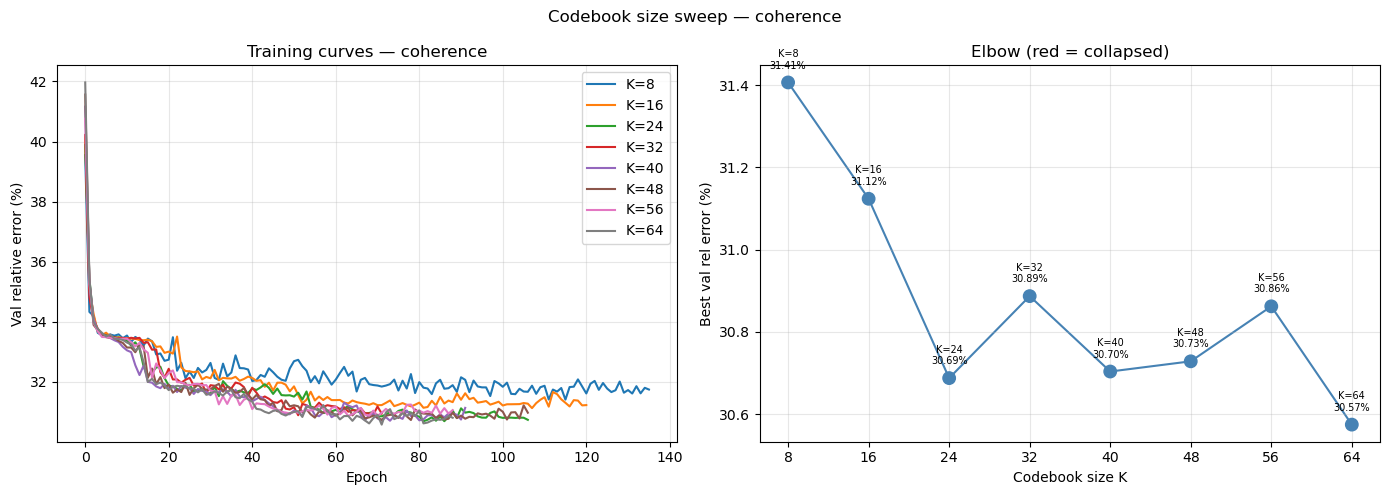

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for K, errs in sweep_errors.items():
    style = '--' if sweep_reasons[K]=='collapse' else '-'
    axes[0].plot([e*100 for e in errs], style,
                 label=f'K={K}'+(' [collapsed]' if sweep_reasons[K]=='collapse' else ''))
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Val relative error (%)')
axes[0].set_title(f'Training curves — {DESCRIPTOR}'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
best   = [min(sweep_errors[K])*100 for K in CODEBOOK_SIZES]
colors = ['tomato' if sweep_reasons[K]=='collapse' else 'steelblue' for K in CODEBOOK_SIZES]
axes[1].plot(CODEBOOK_SIZES, best, color='steelblue', lw=1.5, zorder=1)
axes[1].scatter(CODEBOOK_SIZES, best, c=colors, s=80, zorder=2)
for K, b in zip(CODEBOOK_SIZES, best):
    axes[1].annotate(f'K={K}\n{b:.2f}%', (K, b), textcoords='offset points',
                     xytext=(0,10), ha='center', fontsize=7)
axes[1].set_xlabel('Codebook size K'); axes[1].set_ylabel('Best val rel error (%)')
axes[1].set_title('Elbow (red = collapsed)'); axes[1].set_xticks(CODEBOOK_SIZES)
axes[1].grid(True, alpha=0.3)
plt.suptitle(f'Codebook size sweep — {DESCRIPTOR}'); plt.tight_layout(); plt.show()

## 4. Save handoff bundle

Writes `<prefix>_sweep.pt` holding the full config and every trained sweep model.
`fit_vqvae.py` reads this bundle; the data are re-segmented from the saved config,
so no parameters are re-specified downstream.

In [ ]:
# Assemble the full config the finaliser needs (everything it would otherwise
# have to be told again). The data are re-segmented from DATA_PATH + these values.
config = {
    'subid':            subid,
    'DATA_PATH':        DATA_PATH,
    'FS':               FS,
    'SEGMENT_SEC':      SEGMENT_SEC,
    'SEGMENT_SAMPLES':  SEGMENT_SAMPLES,
    'FILT_DIM':         FILT_DIM,
    'DESCRIPTOR':       DESCRIPTOR,
    'FIXED_BANDS':      FIXED_BANDS,
    'N_FILT':           N_FILT,
    'FREQ_LOW':         FREQ_LOW,
    'FREQ_HIGH':        FREQ_HIGH,
    'MIN_BAND':         MIN_BAND,
    'CUTOFF':           CUTOFF,
    'EFFECTIVE_N_FILT': EFFECTIVE_N_FILT,
    'C':                C,
    'CODEBOOK_SIZES':   list(CODEBOOK_SIZES),
    'TOKENISE_STEP_SAMPLES': TOKENISE_STEP_SAMPLES,
    'PRUNE_PCT':        PRUNE_PCT,
    'VAL_FRACTION':     VAL_FRACTION,
    'CODEBOOK_DIM':     CODEBOOK_DIM,
    'DECODER_HIDDEN':   DECODER_HIDDEN,
    'ENCODER_HIDDEN':   ENCODER_HIDDEN,
    'BATCH_SIZE':       BATCH_SIZE,
    'LR':               LR,
    'SWEEP_EPOCHS':     SWEEP_EPOCHS,
    'FULL_EPOCHS':      FULL_EPOCHS,
    'PATIENCE':         PATIENCE,
}

# trained sweep model per K (state dicts), plus histories/reasons/errors
sweep_state      = {K: sweep_models[K].state_dict()        for K in CODEBOOK_SIZES}
sweep_best_err   = [min(sweep_errors[K]) for K in CODEBOOK_SIZES]

bundle_path = f'{subid}_{DESCRIPTOR}_seg{SEGMENT_SEC}s_sweep.pt'
torch.save({
    'config':           config,
    'sweep_state':      sweep_state,
    'sweep_histories':  sweep_histories,
    'sweep_reasons':    sweep_reasons,
    'sweep_best_err':   sweep_best_err,
}, bundle_path)
print('saved handoff bundle:', bundle_path)
print('next:  python fit_vqvae.py --sweep', bundle_path, '--codebook-size <K>')
